# Ronda011b — accuracy principal, F1 macro control
Análisis de una ejecución cerrada; resultados de selección, no prueba externa.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
from IPython.display import display,Markdown
if not Path('reports/registro_011b.json').exists():os.chdir('..')
r=json.loads(Path('reports/registro_011b.json').read_text())
display(Markdown(Path('reports/resumen_011b.md').read_text()))
cv=pd.read_csv('reports/resultados_011b.csv')
display(cv)
display(pd.read_csv('reports/criterios_011b.csv'))
display(r['historical'])

# Ronda011b: revisión de010 y alternativas clásicas

Accuracy es el criterio principal y F1 macro es un control, por confirmación explícita del usuario el9 de octubre de2026. Público010: **0,89777**. Público011: desconocido.

## Qué mejoró en010

La entrega010 corresponde al experimento013: conserva TF-IDF de discurso y posición, y LinearSVC L1, pero cambia C=1 por C=2. La menor regularización elevó la accuracy OOF media de0,895660 a0,899062 y la brecha de0,060799 a0,088976. El modelo pasó de3252 a5491 coeficientes no nulos. Mejoró el público de0,89555 a0,89777, a costa de más ajuste al entrenamiento. Los hashes y la recarga del modelo010 se verificaron antes de comparar.

## Investigación e implementación

Ver [investigacion_011b.md](investigacion_011b.md) para fuentes primarias y decisiones. Se implementaron presencia binaria con/sin IDF, TF sublineal sin IDF, identidad de conectores con L1 y regresión logística L1. No se incorporaron datos externos. La ronda011 previa se preserva.

## Resultados de selección

| Candidata | Accuracy media OOF | F1 macro medio OOF | Brecha accuracy | Folds ganados vs010 |
|---|---:|---:|---:|---:|
| ref010 | 0.899062 | 0.903358 | 0.088976 | — |
| binary_idf | 0.898611 | 0.902981 | 0.090000 | 4/9 |
| connector_l1 | 0.898333 | 0.902623 | 0.090295 | 3/9 |
| binary_noidf | 0.893403 | 0.897798 | 0.083611 | 0/9 |
| tf_noidf | 0.893056 | 0.897346 | 0.080347 | 0/9 |
| logistic_l1 | 0.892743 | 0.896763 | 0.065799 | 0/9 |

Semillas8803/9901/11003, tres folds agrupados por semilla. Los puntajes OOF se calculan sobre las9600 predicciones de desarrollo de cada semilla y luego se promedian. La brecha promedia accuracy de entrenamiento menos validación por fold.

## Criterio fijado antes de entrenar

>=7/9 folds accuracy; delta medio accuracy >=0.003; delta F1 medio >=0; brecha accuracy media no mayor; no perder accuracy ni F1 en137.

La comparación137 es otra puerta de selección, no una prueba independiente.

## Decisión

Ganadora: **ninguna**. CSV creado: **False**.

Conservar010: ninguna candidata supera los criterios. No crear un envío equivalente ni bajar umbrales a posteriori.

## Límites y controles

No se usó el test local histórico para elegir ni eval para ajustar. Todos los vocabularios, IDF y coeficientes se aprendieron dentro del entrenamiento de cada fold. Grupos de texto normalizado disjuntos; esa agrupación no garantiza detectar duplicados semánticos. Convergencia exigida. Artefactos previos preservados por hash.

Los datos de desarrollo se han explorado repetidamente. Estos scores sirven para selección y pueden ser optimistas; las nuevas semillas no crearían datos vírgenes. Los9folds no son independientes ni se presenta un test de significación a partir de contar victorias. Menor brecha es un diagnóstico, no una garantía de ausencia de sobreajuste.

Que una métrica local coincida numéricamente con un score público no demuestra cuál es la métrica oficial. Aquí accuracy se usa por instrucción directa del usuario. Tampoco los experimentos negativos previos prueban un techo absoluto para ML clásico. No se promete0,90 público.

## Reproducibilidad

Tiempo de experimento: 549.8 segundos. Artefactos anteriores intactos: True.

Entrenamiento: `.venv/bin/python -m src.experimento_011b`. La ejecución se detiene si ya existe el registro o el destino del modelo/envío. Informe y notebook: `.venv/bin/python -m src.informe_011b`. El notebook analiza resultados guardados, no vuelve a entrenar.

Archivos de auditoría: `plan_011b.json`, `registro_011b.json`, `folds_011b.csv`, `resultados_011b.csv`, `criterios_011b.csv` y `predicciones_oof_011b.csv`.


,name,seed,accuracy,f1,gap
0,ref010,8803,0.900937,0.905185,0.087135
1,binary_idf,8803,0.900937,0.905283,0.087760
2,binary_noidf,8803,0.895104,0.899573,0.081979
3,tf_noidf,8803,0.893646,0.897921,0.079844
4,connector_l1,8803,0.899271,0.903554,0.088906
5,logistic_l1,8803,0.893021,0.896969,0.065625
6,ref010,9901,0.898333,0.902597,0.089427
7,binary_idf,9901,0.896979,0.901325,0.091667
8,binary_noidf,9901,0.892604,0.896897,0.083802
9,tf_noidf,9901,0.894167,0.898357,0.078698


,name,accuracy_gain,f1_gain,gap_change,folds_won,passes
0,binary_idf,-0.000451,-0.000377,0.001024,4,False
1,binary_noidf,-0.005660,-0.005560,-0.005365,0,False
2,tf_noidf,-0.006007,-0.006012,-0.008628,0,False
3,connector_l1,-0.000729,-0.000735,0.001319,3,False
4,logistic_l1,-0.006319,-0.006595,-0.023177,0,False


{}

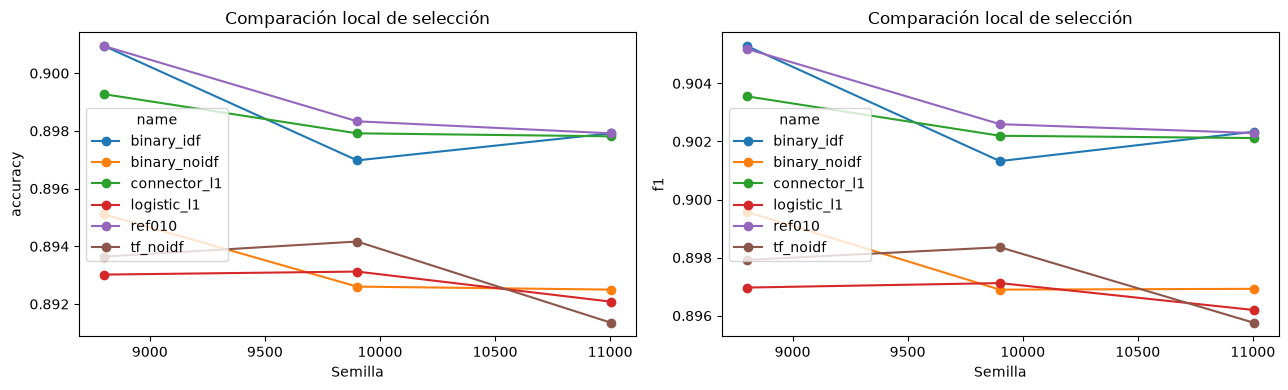

,name,seed,fold,train_accuracy,validation_accuracy,train_f1,validation_f1,gap,seconds
0,ref010,8803,0,0.986250,0.898438,0.986914,0.903013,0.087812,8.340887
1,ref010,8803,1,0.989219,0.900000,0.989719,0.904022,0.089219,9.090856
2,ref010,8803,2,0.988750,0.904375,0.989314,0.908525,0.084375,9.040798
3,binary_idf,8803,0,0.986875,0.896875,0.987507,0.901608,0.090000,7.441568
4,binary_idf,8803,1,0.990625,0.902500,0.991069,0.906621,0.088125,7.466853
5,binary_idf,8803,2,0.988594,0.903438,0.989166,0.907622,0.085156,7.360028
6,binary_noidf,8803,0,0.975156,0.888125,0.976345,0.892824,0.087031,13.615688
7,binary_noidf,8803,1,0.979531,0.897813,0.980502,0.902145,0.081719,14.969648
8,binary_noidf,8803,2,0.976562,0.899375,0.977692,0.903693,0.077187,16.567278
9,tf_noidf,8803,0,0.971250,0.887188,0.972634,0.891729,0.084062,14.367949


In [2]:
import matplotlib.pyplot as plt
main=cv[cv.seed.isin(r['plan']['seeds'])]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['accuracy','f1']):
 main.pivot(index='seed',columns='name',values=metric).plot(marker='o',ax=ax)
 ax.set(xlabel='Semilla',ylabel=metric,title='Comparación local de selección')
plt.tight_layout();plt.savefig('reports/comparacion_011b.png',dpi=160);plt.show()
display(pd.read_csv('reports/folds_011b.csv'))

In [3]:
display(r['source_sha256'])
print('Artefactos anteriores intactos:',r['old_artifacts_unchanged'])
if r['submission_created']:
 display(r['artifacts_sha256'])
 display(pd.read_csv('submissions/submission_011.csv').head())
else:print(r['decision'])

{'src/experimento_011b.py': '5bf4915901aa2a7e53fc45df3141080dfded23e802a76e271d7b1e61e2ebd3f0',
 'src/modelos_011b.py': '93ad432001896cd47d1a7b556aa84c1e8fb6b478d1f751d2841b03acb2609f0d',
 'src/modelos_008b.py': '71774e20c9b62a8f63310156b6d498165168d99dd82980919d9d9481c93f5d91',
 'src/features_007b.py': '32168dc3045b8b146e3260ddfb8b04c3153e1210ade017050ec2243fe7c3daa3',
 'reports/particiones.csv': 'd90cbd30a92a366298a66f2322df4869694798392f19b9c0978dbecac104a931'}

Artefactos anteriores intactos: True
Conservar010: ninguna candidata supera los criterios. No crear un envío equivalente ni bajar umbrales a posteriori.
